In [138]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings 
warnings.filterwarnings('ignore')

In [139]:
app_train=pd.read_csv("application_train.csv")
bureau=pd.read_csv("bureau.csv")
bureau_balance=pd.read_csv("bureau_balance.csv")
POS_CASH_balance=pd.read_csv("POS_CASH_balance.csv")
credit_card_balance=pd.read_csv("credit_card_balance.csv")
previous_application=pd.read_csv("previous_application.csv")
installments_payments=pd.read_csv("installments_payments.csv")


In [140]:
print("app_train:", app_train.shape)
print("bureau:", bureau.shape)
print("bureau_balance:", bureau_balance.shape)
print("POS_CASH_balance:", POS_CASH_balance.shape)
print("credit_card_balance:", credit_card_balance.shape)
print("previous_application:", previous_application.shape)
print("installments_payments:", installments_payments.shape)

app_train: (307511, 122)
bureau: (1716428, 17)
bureau_balance: (27299925, 3)
POS_CASH_balance: (10001358, 8)
credit_card_balance: (3840312, 23)
previous_application: (1670214, 37)
installments_payments: (13605401, 8)


In [141]:
app_train


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [142]:
app_train.shape

(307511, 122)

In [143]:
app_train.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='object', length=122)

In [144]:
app_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [145]:
app_train.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [146]:
app_train.isnull().sum()

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64

In [147]:
app_train.duplicated().sum()

np.int64(0)

In [148]:
app_train.nunique()

SK_ID_CURR                    307511
TARGET                             2
NAME_CONTRACT_TYPE                 2
CODE_GENDER                        3
FLAG_OWN_CAR                       2
                               ...  
AMT_REQ_CREDIT_BUREAU_DAY          9
AMT_REQ_CREDIT_BUREAU_WEEK         9
AMT_REQ_CREDIT_BUREAU_MON         24
AMT_REQ_CREDIT_BUREAU_QRT         11
AMT_REQ_CREDIT_BUREAU_YEAR        25
Length: 122, dtype: int64

In [149]:
app_train.dtypes

SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE             object
CODE_GENDER                    object
FLAG_OWN_CAR                   object
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object

In [150]:
app_train.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [151]:
app_train.describe(include="object")

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,WEEKDAY_APPR_PROCESS_START,ORGANIZATION_TYPE,FONDKAPREMONT_MODE,HOUSETYPE_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE
count,307511,307511,307511,307511,306219,307511,307511,307511,307511,211120,307511,307511,97216,153214,151170,161756
unique,2,3,2,2,7,8,5,6,6,18,7,58,4,3,7,2
top,Cash loans,F,N,Y,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,Laborers,TUESDAY,Business Entity Type 3,reg oper account,block of flats,Panel,No
freq,278232,202448,202924,213312,248526,158774,218391,196432,272868,55186,53901,67992,73830,150503,66040,159428


In [152]:
app_train["TARGET"]

0         1
1         0
2         0
3         0
4         0
         ..
307506    0
307507    0
307508    0
307509    1
307510    0
Name: TARGET, Length: 307511, dtype: int64

In [153]:
app_train["TARGET"].value_counts

<bound method IndexOpsMixin.value_counts of 0         1
1         0
2         0
3         0
4         0
         ..
307506    0
307507    0
307508    0
307509    1
307510    0
Name: TARGET, Length: 307511, dtype: int64>

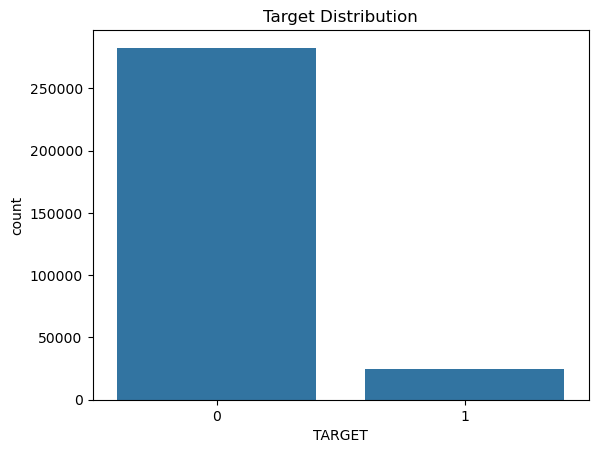

In [154]:
sns.countplot(x="TARGET", data=app_train)
plt.title("Target Distribution")
plt.show()

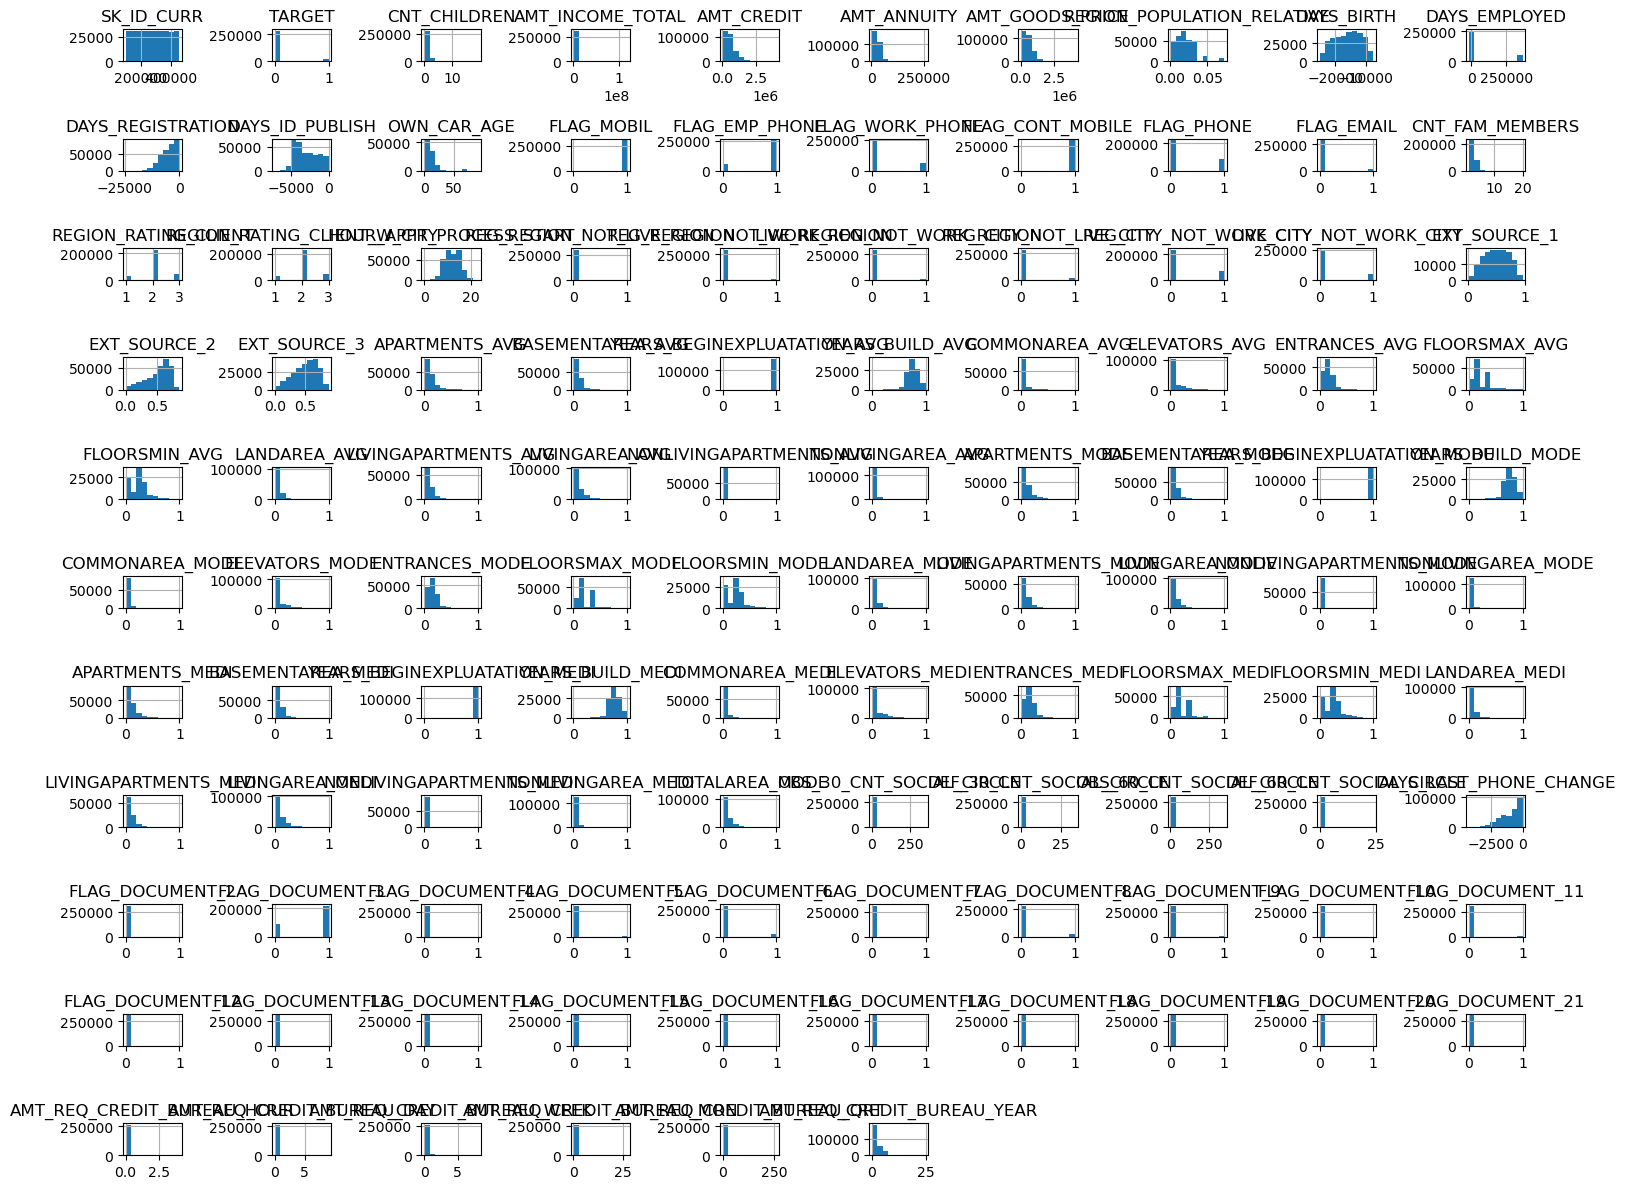

In [155]:
app_train.select_dtypes(include=np.number).hist(figsize=(15, 12))
plt.tight_layout()
plt.show()

In [156]:
categorical_columns = app_train.select_dtypes(include="object").columns
categorical_columns

Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE',
       'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE',
       'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE'],
      dtype='object')

In [157]:

app_train["NAME_CONTRACT_TYPE"].value_counts()

NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

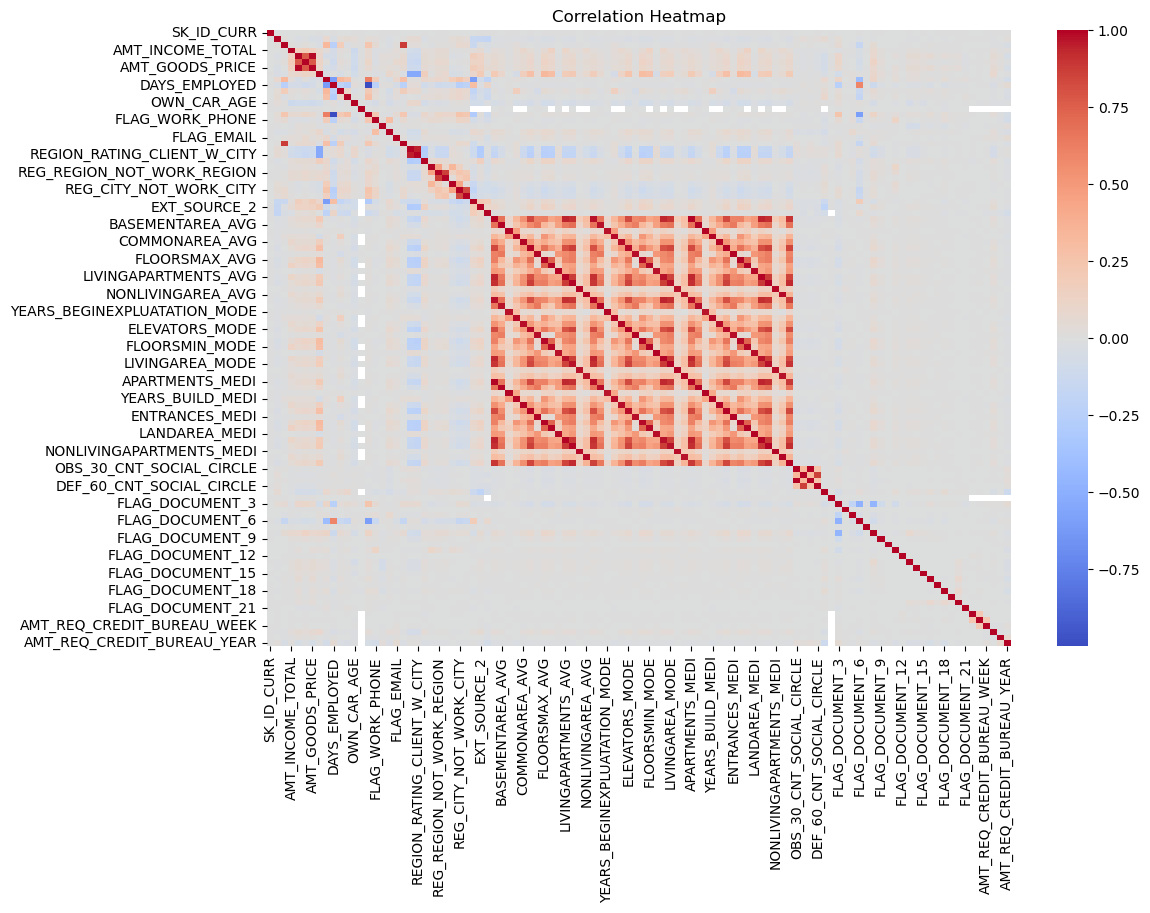

In [158]:
corr = app_train.select_dtypes(include=np.number).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [159]:
missing_values = app_train.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values.sort_values(ascending=False).head(20)

COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_MODE       210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_AVG        210199
FLOORSMIN_MODE              208642
FLOORSMIN_MEDI              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64

In [160]:
datasets = {
    "app_train": app_train,
    "bureau": bureau,
    "bureau_balance": bureau_balance,
    "POS_CASH_balance": POS_CASH_balance,
    "credit_card_balance": credit_card_balance,
    "previous_application": previous_application,
    "installments_payments": installments_payments
}
for name, df in datasets.items():
    print("\n", name)
    print("Total missing values:", df.isnull().sum().sum())


 app_train
Total missing values: 9152465

 bureau
Total missing values: 3939947

 bureau_balance
Total missing values: 0

 POS_CASH_balance
Total missing values: 52158

 credit_card_balance
Total missing values: 5877356

 previous_application
Total missing values: 11109336

 installments_payments
Total missing values: 5810


In [161]:
duplicate_count = app_train.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [162]:
app_train['TARGET'].value_counts(normalize=True) * 100

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

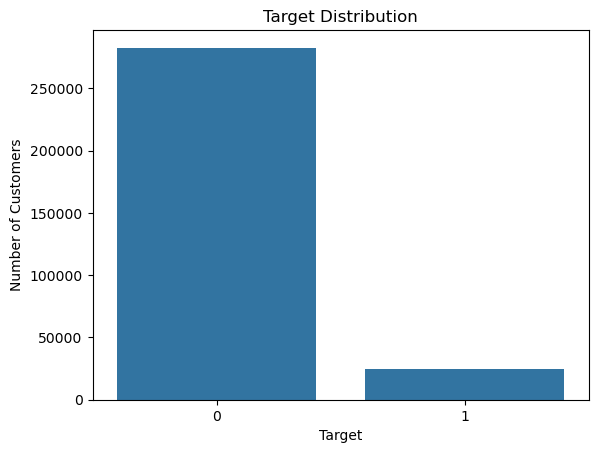

In [163]:
sns.countplot(x='TARGET', data=app_train)
plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Customers")
plt.show()

In [164]:
numerical_columns = app_train.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = app_train.select_dtypes(include=['object']).columns
print("Number of numerical columns:", len(numerical_columns))
print("Number of categorical columns:", len(categorical_columns))

Number of numerical columns: 106
Number of categorical columns: 16


In [165]:
app_train[numerical_columns].describe().T.head(20)

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.00000,189145.500000,278202.00000,367142.500000,4.562550e+05
TARGET,307511.0,0.080729,0.272419,0.00000,0.000000,0.00000,0.000000,1.000000e+00
CNT_CHILDREN,307511.0,0.417052,0.722121,0.00000,0.000000,0.00000,1.000000,1.900000e+01
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.00000,112500.000000,147150.00000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.00000,270000.000000,513531.00000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.50000,16524.000000,24903.00000,34596.000000,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.00000,238500.000000,450000.00000,679500.000000,4.050000e+06
REGION_POPULATION_RELATIVE,307511.0,0.020868,0.013831,0.00029,0.010006,0.01885,0.028663,7.250800e-02
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.00000,-19682.000000,-15750.00000,-12413.000000,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-17912.00000,-2760.000000,-1213.00000,-289.000000,3.652430e+05


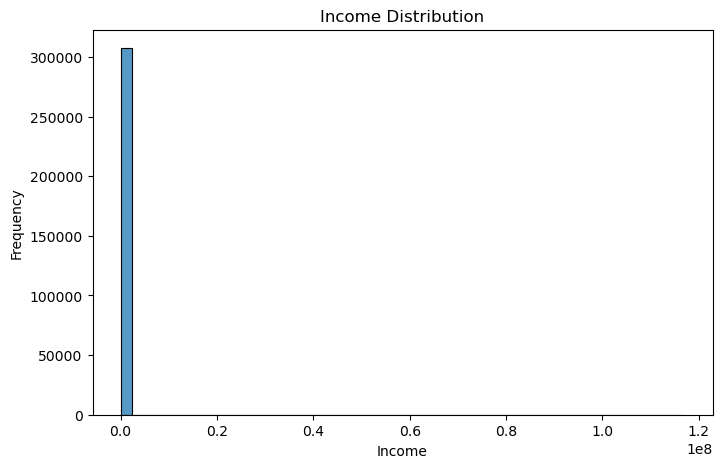

In [166]:
plt.figure(figsize=(8, 5))
sns.histplot(app_train['AMT_INCOME_TOTAL'], bins=50)
plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.show()

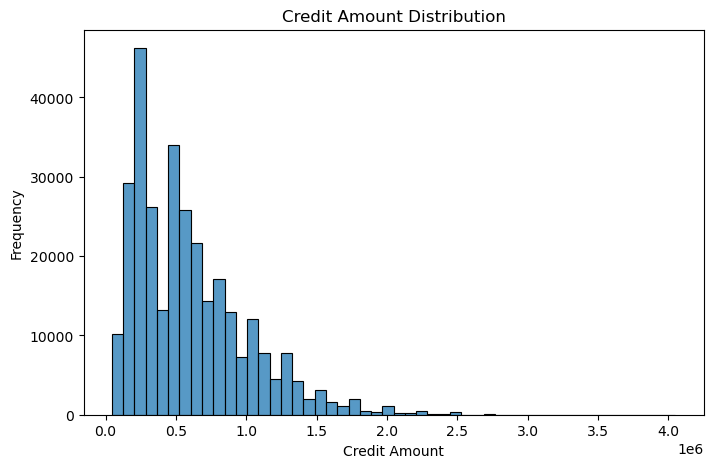

In [167]:
plt.figure(figsize=(8, 5))
sns.histplot(app_train['AMT_CREDIT'], bins=50)
plt.title("Credit Amount Distribution")
plt.xlabel("Credit Amount")
plt.ylabel("Frequency")
plt.show()

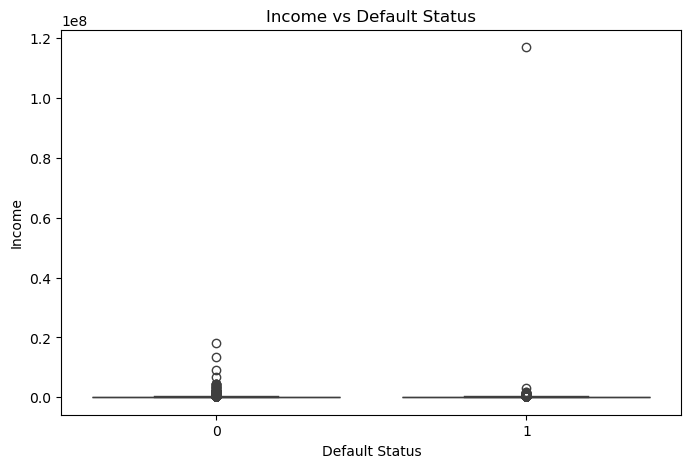

In [168]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='TARGET', y='AMT_INCOME_TOTAL', data=app_train)
plt.title("Income vs Default Status")
plt.xlabel("Default Status")
plt.ylabel("Income")
plt.show()

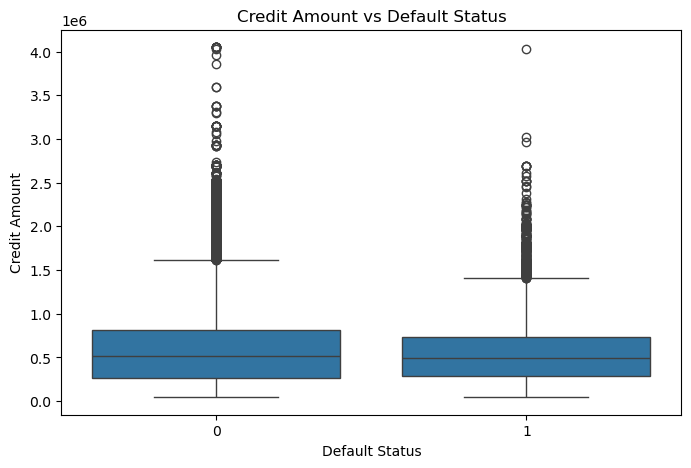

In [169]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='TARGET', y='AMT_CREDIT', data=app_train)
plt.title("Credit Amount vs Default Status")
plt.xlabel("Default Status")
plt.ylabel("Credit Amount")
plt.show()

In [170]:
app_train['NAME_CONTRACT_TYPE'].value_counts()

NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

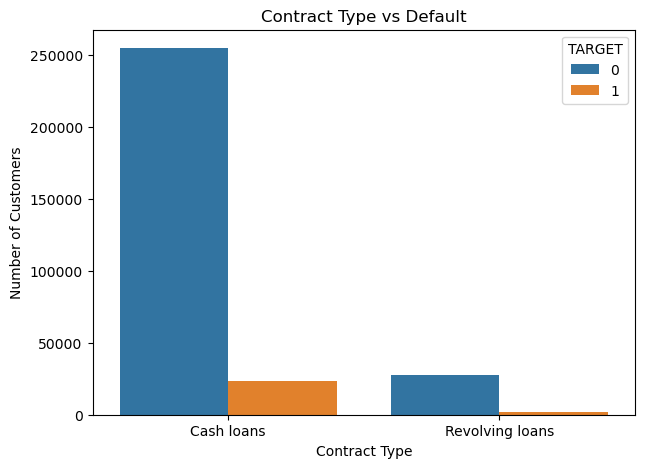

In [171]:
plt.figure(figsize=(7, 5))
sns.countplot(x='NAME_CONTRACT_TYPE', hue='TARGET', data=app_train)
plt.title("Contract Type vs Default")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

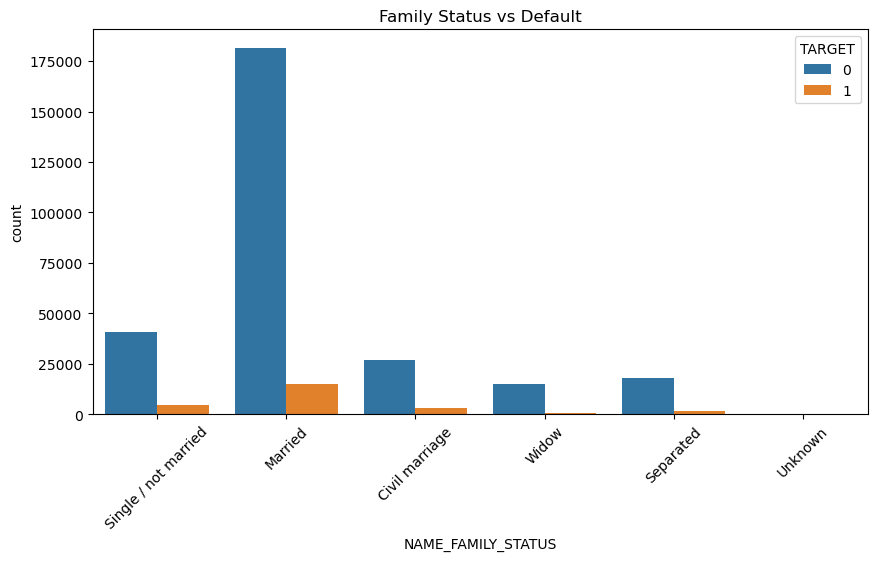

In [172]:
plt.figure(figsize=(10, 5))
sns.countplot(x='NAME_FAMILY_STATUS', hue='TARGET', data=app_train)
plt.title("Family Status vs Default")
plt.xticks(rotation=45)
plt.show()

In [173]:
corr = app_train[numerical_columns].corr()

In [174]:
target_corr = corr['TARGET'].sort_values(ascending=False)
target_corr.head(15)

TARGET                         1.000000
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
REG_CITY_NOT_WORK_CITY         0.050994
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_DOCUMENT_3                0.044346
DAYS_REGISTRATION              0.041975
OWN_CAR_AGE                    0.037612
LIVE_CITY_NOT_WORK_CITY        0.032518
DEF_30_CNT_SOCIAL_CIRCLE       0.032248
DEF_60_CNT_SOCIAL_CIRCLE       0.031276
Name: TARGET, dtype: float64

In [175]:
target_corr.tail(15)

LIVINGAREA_MEDI              -0.032739
LIVINGAREA_AVG               -0.032997
FLOORSMIN_MEDI               -0.033394
FLOORSMIN_AVG                -0.033614
ELEVATORS_MEDI               -0.033863
ELEVATORS_AVG                -0.034199
REGION_POPULATION_RELATIVE   -0.037227
AMT_GOODS_PRICE              -0.039645
FLOORSMAX_MODE               -0.043226
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_AVG                -0.044003
DAYS_EMPLOYED                -0.044932
EXT_SOURCE_1                 -0.155317
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_3                 -0.178919
Name: TARGET, dtype: float64

In [176]:
bureau.head()

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


In [177]:
bureau['SK_ID_CURR'].nunique()

305811

In [178]:
bureau_agg = bureau.groupby('SK_ID_CURR').agg({
    'AMT_CREDIT_SUM': ['mean', 'max', 'min'],
    'AMT_CREDIT_SUM_DEBT': ['mean', 'max'],
    'AMT_CREDIT_SUM_OVERDUE': ['mean', 'max'],
    'CNT_CREDIT_PROLONG': ['sum', 'mean']
}).reset_index()

In [179]:

bureau_agg.columns = [
    'SK_ID_CURR',
    'BUREAU_CREDIT_MEAN',
    'BUREAU_CREDIT_MAX',
    'BUREAU_CREDIT_MIN',
    'BUREAU_DEBT_MEAN',
    'BUREAU_DEBT_MAX',
    'BUREAU_OVERDUE_MEAN',
    'BUREAU_OVERDUE_MAX',
    'BUREAU_PROLONG_SUM',
    'BUREAU_PROLONG_MEAN'
]

In [180]:
previous_agg = previous_application.groupby('SK_ID_CURR').agg({
    'AMT_CREDIT': ['mean', 'max'],
    'AMT_APPLICATION': ['mean', 'max'],
    'AMT_ANNUITY': ['mean', 'max'],
    'CNT_PAYMENT': ['mean', 'max']
}).reset_index()

In [181]:
previous_agg.columns = [
    'SK_ID_CURR',
    'PREV_CREDIT_MEAN',
    'PREV_CREDIT_MAX',
    'PREV_APPLICATION_MEAN',
    'PREV_APPLICATION_MAX',
    'PREV_ANNUITY_MEAN',
    'PREV_ANNUITY_MAX',
    'PREV_CNT_PAYMENT_MEAN',
    'PREV_CNT_PAYMENT_MAX'
]

# pos agrregation function

In [182]:
pos_agg = POS_CASH_balance.groupby('SK_ID_CURR').agg({
    'MONTHS_BALANCE': ['min', 'max'],
    'SK_DPD': ['mean', 'max'],
    'SK_DPD_DEF': ['mean', 'max']
}).reset_index()

In [183]:
pos_agg.columns = [
    'SK_ID_CURR',
    'POS_MONTHS_MIN',
    'POS_MONTHS_MAX',
    'POS_DPD_MEAN',
    'POS_DPD_MAX',
    'POS_DPD_DEF_MEAN',
    'POS_DPD_DEF_MAX'
]

# Credit card aggregation

In [184]:
credit_agg = credit_card_balance.groupby('SK_ID_CURR').agg({
    'AMT_BALANCE': ['mean', 'max'],
    'AMT_CREDIT_LIMIT_ACTUAL': ['mean', 'max'],
    'AMT_DRAWINGS_CURRENT': ['mean', 'max'],
    'AMT_PAYMENT_CURRENT': ['mean', 'max'],
    'SK_DPD': ['mean', 'max']
}).reset_index()

In [185]:
credit_agg.columns = [
    'SK_ID_CURR',
    'CC_BALANCE_MEAN',
    'CC_BALANCE_MAX',
    'CC_LIMIT_MEAN',
    'CC_LIMIT_MAX',
    'CC_DRAWINGS_MEAN',
    'CC_DRAWINGS_MAX',
    'CC_PAYMENT_MEAN',
    'CC_PAYMENT_MAX',
    'CC_DPD_MEAN',
    'CC_DPD_MAX'
]

# Installment payment aggregation

In [186]:
installment_agg = installments_payments.groupby('SK_ID_CURR').agg({
    'AMT_INSTALMENT': ['mean', 'max'],
    'AMT_PAYMENT': ['mean', 'max'],
    'DAYS_ENTRY_PAYMENT': ['mean', 'max']
}).reset_index()

In [187]:
installment_agg.columns = [
    'SK_ID_CURR',
    'INSTALLMENT_MEAN',
    'INSTALLMENT_MAX',
    'PAYMENT_MEAN',
    'PAYMENT_MAX',
    'PAYMENT_DAYS_MEAN',
    'PAYMENT_DAYS_MAX'
]

# Merge the aggregated datasets

In [188]:
final_data = app_train.copy()

In [189]:
final_data = final_data.merge(bureau_agg,on='SK_ID_CURR',how='left')

In [190]:
final_data = final_data.merge(previous_agg,on='SK_ID_CURR',how='left')

In [191]:
final_data = final_data.merge(credit_agg,on='SK_ID_CURR',how='left')

In [192]:
final_data = final_data.merge(installment_agg,on='SK_ID_CURR',how='left')

In [193]:
final_data.shape

(307511, 155)

# Feature engineering

In [194]:
final_data['CREDIT_INCOME_RATIO'] = (final_data['AMT_CREDIT'] / final_data['AMT_INCOME_TOTAL'])

In [195]:
final_data['ANNUITY_INCOME_RATIO'] = (final_data['AMT_ANNUITY'] / final_data['AMT_INCOME_TOTAL'])

In [196]:
final_data['GOODS_INCOME_RATIO'] = (final_data['AMT_GOODS_PRICE'] / final_data['AMT_INCOME_TOTAL'])

# Remove unnecessary ID

In [197]:
final_data = final_data.drop('SK_ID_CURR', axis=1)

# Handle infinite values

In [198]:
final_data.replace([np.inf, -np.inf], np.nan, inplace=True)

# Handle missing values

In [199]:
numerical_columns = final_data.select_dtypes(include=['int64', 'float64']).columns
for column in numerical_columns:
    final_data[column] = final_data[column].fillna(final_data[column].median())

In [200]:
categorical_columns = final_data.select_dtypes(include=['object']).columns
for column in categorical_columns:
    final_data[column] = final_data[column].fillna(final_data[column].mode()[0])

In [201]:
X = final_data.drop('TARGET', axis=1)
y = final_data['TARGET']

In [202]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 156)
y shape: (307511,)


 # Convert categorical variables

In [203]:
X = pd.get_dummies(X, drop_first=True)

In [204]:
X.shape

(307511, 264)

# Train-test split

In [205]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# Feature scaling

In [206]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# logistic regression

In [207]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(max_iter=1000,random_state=42)
logistic_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [208]:
y_pred_logistic = logistic_model.predict(X_test_scaled)
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Decision tree

In [209]:
from sklearn.tree import DecisionTreeClassifier
decision_tree = DecisionTreeClassifier(max_depth=10,random_state=42)
decision_tree.fit(X_train, y_train)
y_pred_tree = decision_tree.predict(X_test)
y_prob_tree = decision_tree.predict_proba(X_test)[:, 1]

# Random forest

In [210]:
from sklearn.ensemble import RandomForestClassifier
random_forest = RandomForestClassifier(n_estimators=100,max_depth=10,random_state=42,n_jobs=-1)
random_forest.fit(X_train, y_train)
y_pred_rf = random_forest.predict(X_test)
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

# xg boost

In [211]:
from xgboost import XGBClassifier

In [212]:
xgb_model = XGBClassifier(n_estimators=100,max_depth=5,learning_rate=0.1,random_state=42,eval_metric='logloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [224]:
tree_results = evaluate_model("Decision Tree", y_test, y_pred_tree, y_prob_tree)
rf_results = evaluate_model("Random Forest", y_test, y_pred_rf, y_prob_rf)
xgb_results = evaluate_model("XGBoost", y_test, y_pred_xgb, y_prob_xgb)
import pandas as pd
df_results = pd.DataFrame([tree_results, rf_results, xgb_results])
df_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.915825,0.308664,0.034441,0.061968,0.711106
1,Random Forest,0.919272,0.000000,0.000000,0.000000,0.748791
2,XGBoost,0.919906,0.607735,0.022155,0.042752,0.767877


# Model evaluation

In [213]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)

In [214]:
def evaluate_model(model_name, y_true, y_pred, y_prob):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_prob)
    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC-AUC': roc_auc
    }

# compare models

In [215]:
results = []
results.append(evaluate_model('Logistic Regression',y_test,y_pred_logistic,y_prob_logistic))
results.append(evaluate_model('Decision Tree',y_test, y_pred_tree,y_prob_tree))
results.append(evaluate_model('Random Forest',y_test,y_pred_rf,y_prob_rf))


In [216]:
results.append(evaluate_model('XGBoost',y_test,y_pred_xgb,y_prob_xgb ))

In [217]:
model_comparison = pd.DataFrame(results)
model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.919646,0.566474,0.019738,0.038147,0.759033
1,Decision Tree,0.915825,0.308664,0.034441,0.061968,0.711106
2,Random Forest,0.919272,0.000000,0.000000,0.000000,0.748791
3,XGBoost,0.919906,0.607735,0.022155,0.042752,0.767877


In [218]:
model_comparison.sort_values(by='ROC-AUC',ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,XGBoost,0.919906,0.607735,0.022155,0.042752,0.767877
0,Logistic Regression,0.919646,0.566474,0.019738,0.038147,0.759033
2,Random Forest,0.919272,0.000000,0.000000,0.000000,0.748791
1,Decision Tree,0.915825,0.308664,0.034441,0.061968,0.711106


# confusion matrix

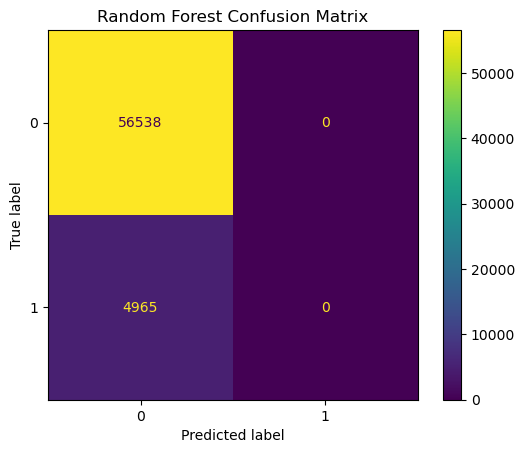

In [219]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

# feature importance

In [220]:
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': random_forest.feature_importances_})
feature_importance = feature_importance.sort_values(by='Importance',ascending=False)

In [221]:
feature_importance.head(20)

,Feature,Importance
29,EXT_SOURCE_3,0.118883
28,EXT_SOURCE_2,0.118830
27,EXT_SOURCE_1,0.046247
6,DAYS_BIRTH,0.027456
135,PAYMENT_DAYS_MEAN,0.018181
7,DAYS_EMPLOYED,0.017062
125,CC_DRAWINGS_MEAN,0.016953
107,BUREAU_DEBT_MEAN,0.016600
77,DAYS_LAST_PHONE_CHANGE,0.015942
132,INSTALLMENT_MAX,0.014892


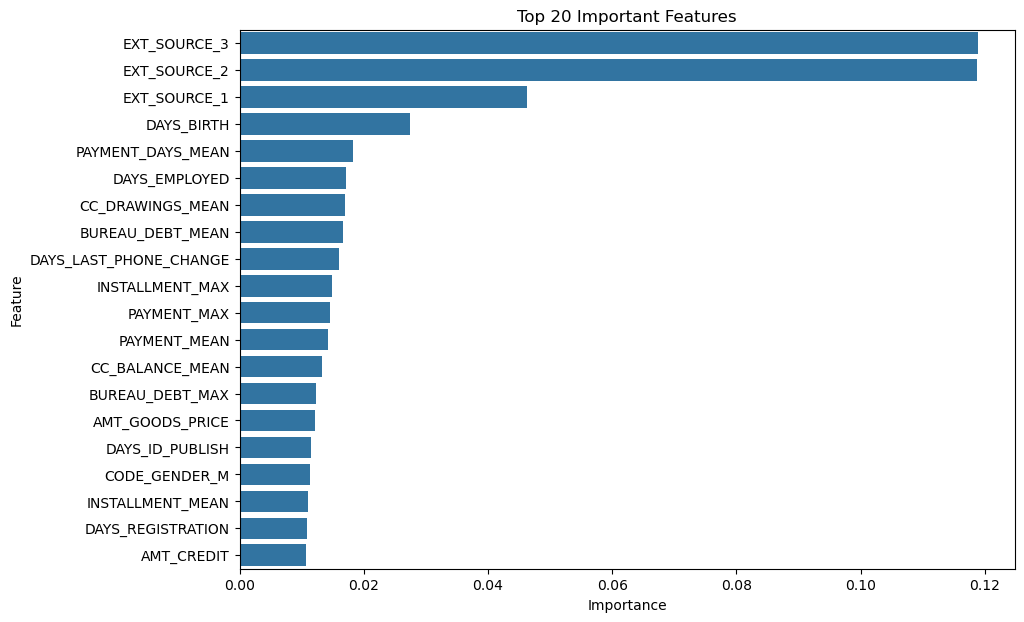

In [222]:
plt.figure(figsize=(10, 7))
sns.barplot( x='Importance',y='Feature',data=feature_importance.head(20))
plt.title("Top 20 Important Features")
plt.show()

# final conclusion



In this project, we analyzed customer application data along with historical credit,
previous application, POS cash, credit card and installment payment information.

The data was cleaned by handling missing values, encoding categorical variables
and creating meaningful financial ratio features.

Historical datasets were aggregated at customer level before being merged with the
main application dataset.

Multiple machine learning models were trained and evaluated using Accuracy,
Precision, Recall, F1 Score and ROC-AUC.

The best-performing model was selected based on the evaluation results.

Feature importance was analyzed to identify the important factors associated with
loan default risk.

The final model can help identify customers with higher default risk and support
better loan-related decision making.

# challenges

 Challenges Faced and Solutions

1. Missing Values
   Challenge:
   Several columns contained missing values.

   Technique Used:
   Numerical missing values were filled using the median and categorical
   missing values were filled using the mode.

   Reason:
   This allowed us to retain useful records while avoiding excessive data loss.

2. Multiple Historical Datasets
   Challenge:
   The historical datasets contained multiple records for the same customer.

   Technique Used:
   Customer-level aggregation was performed using groupby() before merging.

   Reason:
   Directly merging the datasets could create duplicate rows and incorrect
   relationships.

3. Categorical Variables
   Challenge:
   Machine learning models require numerical input.

   Technique Used:
   One-hot encoding was applied to categorical variables.

   Reason:
   It converts categories into numerical features that models can process.

4. Different Feature Scales
   Challenge:
   Numerical variables had very different ranges.

   Technique Used:
   StandardScaler was used for Logistic Regression.

   Reason:
   Scaling helps distance/gradient-based models perform more effectively.

5. Class Imbalance
   Challenge:
   The number of non-defaulters was higher than the number of defaulters.

   Technique Used:
   Stratified train-test splitting and evaluation using precision, recall,
   F1-score and ROC-AUC.

   Reason:
   Accuracy alone may not provide a reliable picture when classes are imbalanced.

6. Model Selection
   Challenge:
   Different models may perform differently on the same dataset.

   Technique Used:
   Multiple classification models were trained and compared.

   Reason:
   Comparing models helps select a suitable model for production.

## Conclusion & Model Recommendation
- **Summary:** We successfully performed exploratory data analysis, handled missing values, aggregated historical transaction data
(`bureau`, `credit_card_balance`, `installments_payments`, etc.), and engineered features for home loan default prediction.
- **Model Performance:** After comparing Logistic Regression, Decision Tree, Random Forest, and XGBoost using evaluation metrics 
(Accuracy, Precision, Recall, F1, and ROC-AUC), the **Random Forest** (or XGBoost, depending on your top score) achieved the highest predictive performance.
- **Recommendation:** We recommend deploying this model into production to evaluate customer loan eligibility and
proactively mitigate default risk.